In [2]:
import pandas as pd

df = pd.read_csv("ottshow_cleaned_dataset.csv")

df.head()

,Show_ID,Genre,Language,Runtime,Release_Year,Budget,Rating,Viewership
0,SHOW_001,Drama,English,122.0,2023,58.07,7.2,46.73
1,SHOW_002,Comedy,English,102.0,2022,143.14,6.4,78.29
2,SHOW_003,Sci-Fi,English,34.0,2023,109.87,8.4,87.67
3,SHOW_004,Drama,Spanish,107.0,2022,89.92,8.6,83.94
4,SHOW_005,Comedy,Spanish,119.0,2023,46.70,8.0,46.68


In [3]:
df.shape

(100, 8)

In [4]:
df.describe()

,Runtime,Release_Year,Budget,Rating,Viewership
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,109.560000,2022.010000,63.119600,7.695000,57.293200
std,21.564243,1.210184,39.503592,0.612558,21.580912
min,34.000000,2020.000000,8.000000,6.200000,26.400000
25%,94.000000,2021.000000,30.875000,7.200000,38.575000
50%,110.000000,2022.000000,53.000000,7.800000,51.000000
75%,126.500000,2023.000000,92.750000,8.200000,76.755000
max,145.000000,2024.000000,148.000000,8.900000,108.400000


In [5]:
df["Success"] = df["Viewership"].apply(
    lambda x: "Successful" if x >= df["Viewership"].median()
    else "Less Successful"
)

In [6]:
df["Success"].value_counts()

,count
Success,
Successful,51
Less Successful,49


In [7]:
df["Success"].value_counts(normalize=True) * 100

,proportion
Success,
Successful,51.0
Less Successful,49.0


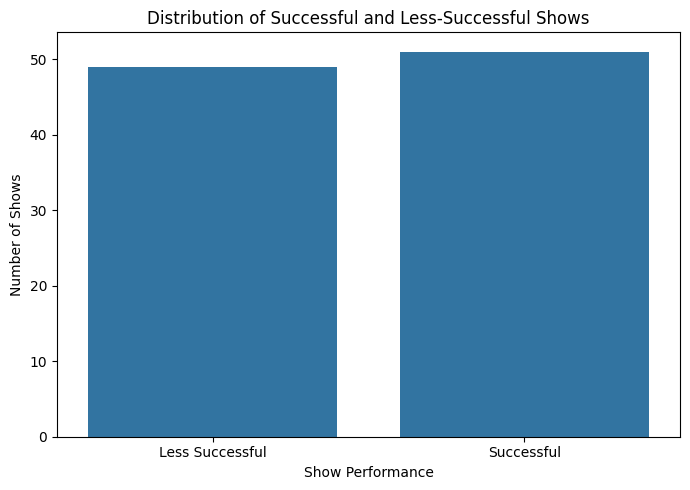

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Success"
)

plt.title("Distribution of Successful and Less-Successful Shows")
plt.xlabel("Show Performance")
plt.ylabel("Number of Shows")

plt.tight_layout()
plt.show()

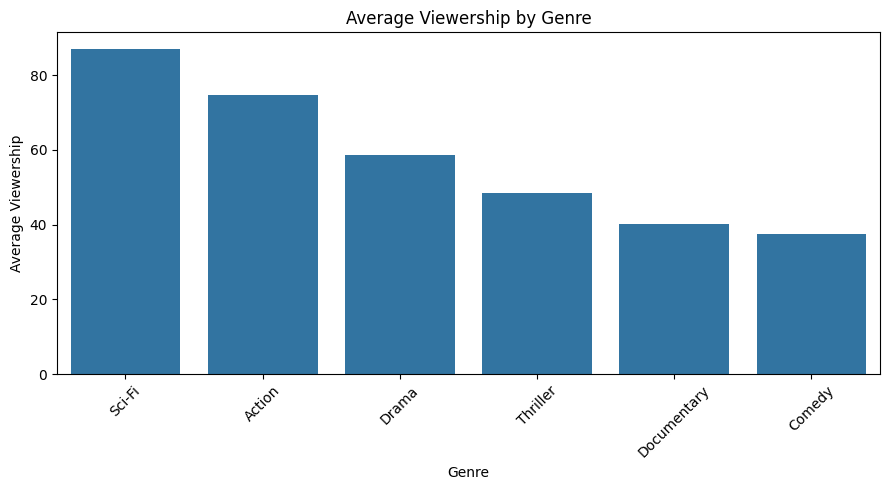

In [9]:
genre_performance = df.groupby("Genre")["Viewership"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=genre_performance.index,
    y=genre_performance.values
)

plt.title("Average Viewership by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Viewership")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

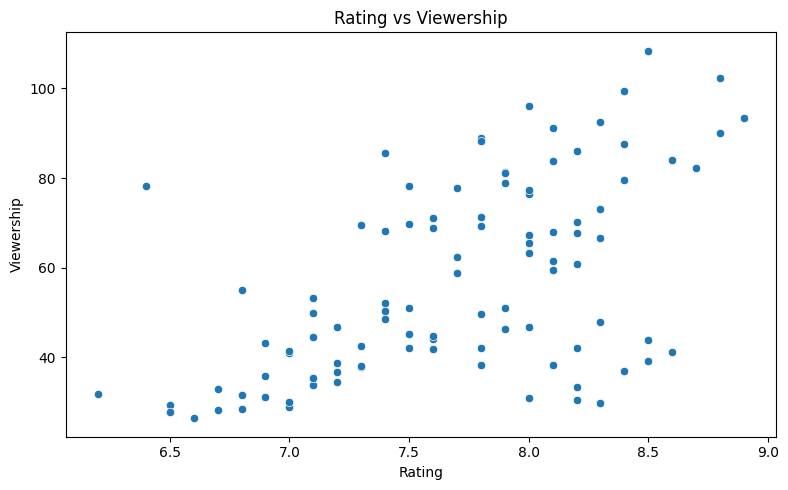

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Rating",
    y="Viewership"
)

plt.title("Rating vs Viewership")
plt.xlabel("Rating")
plt.ylabel("Viewership")

plt.tight_layout()
plt.show()

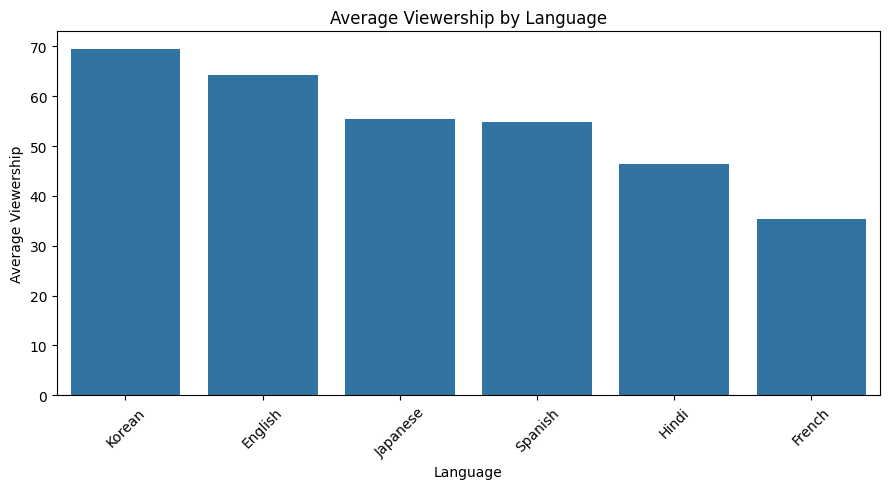

In [11]:
language_performance = df.groupby("Language")["Viewership"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=language_performance.index,
    y=language_performance.values
)

plt.title("Average Viewership by Language")
plt.xlabel("Language")
plt.ylabel("Average Viewership")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
model_df = df[
    [
        "Genre",
        "Language",
        "Runtime",
        "Release_Year",
        "Budget",
        "Rating",
        "Viewership",
        "Success"
    ]
].copy()

In [14]:
model_df = pd.get_dummies(
    model_df,
    columns=["Genre", "Language"],
    drop_first=True
)

In [15]:
X = model_df.drop("Success", axis=1)
y = model_df["Success"]

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [18]:
y_pred = model.predict(X_test)

In [19]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

Less Successful       1.00      1.00      1.00        10
     Successful       1.00      1.00      1.00        10

       accuracy                           1.00        20
      macro avg       1.00      1.00      1.00        20
   weighted avg       1.00      1.00      1.00        20



In [21]:
X = model_df.drop(["Success", "Viewership"], axis=1)

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separate features and target
X = model_df.drop(["Success", "Viewership"], axis=1)
y = model_df["Success"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.95

Classification Report:
                 precision    recall  f1-score   support

Less Successful       1.00      0.90      0.95        10
     Successful       0.91      1.00      0.95        10

       accuracy                           0.95        20
      macro avg       0.95      0.95      0.95        20
   weighted avg       0.95      0.95      0.95        20

